<div align="center">

# Universidad Nacional Abierta y a Distancia – UNAD

### Escuela de Ciencias Básicas, Tecnología e Ingeniería – ECBTI

## Programación para el análisis de datos
**Código del curso:** 203238834

## Tarea 4 – Comunicación de resultados mediante dashboard interactivo
**Dataset:** Calidad del Aire en Colombia (Promedio Anual) – IDEAM / datos.gov.co

<br>

**Presentado por:** Francisco José Velandia Rincón (CC 13174642)

**Grupo:** 03

**Tutor(a):** Andrés Felipe Solís Pino

<br>

Noviembre de 2026

</div>

## 1. Enlaces del proyecto

**Mi dashboard está publicado en:** [PEGAR_AQUI_URL_DE_STREAMLIT](PEGAR_AQUI_URL_DE_STREAMLIT)

**El código fuente está disponible en:** [PEGAR_AQUI_URL_DE_GITHUB](PEGAR_AQUI_URL_DE_GITHUB)

> Ambos enlaces se completan después del despliegue en Streamlit Community Cloud y de subir el repositorio a GitHub.

## 2. Captura del dashboard funcionando

El dashboard tiene: filtros en la barra lateral (departamento, tipo de estación, años y rango de PM2.5), métricas y tabla filtrable (sección *Exploración*), cuatro visualizaciones (por tipo de estación, evolución en el tiempo, PM10 vs PM2.5 y departamentos), la *Validación estadística* (prueba t explicada en lenguaje claro) y los *Hallazgos* con la narrativa para audiencia no técnica.

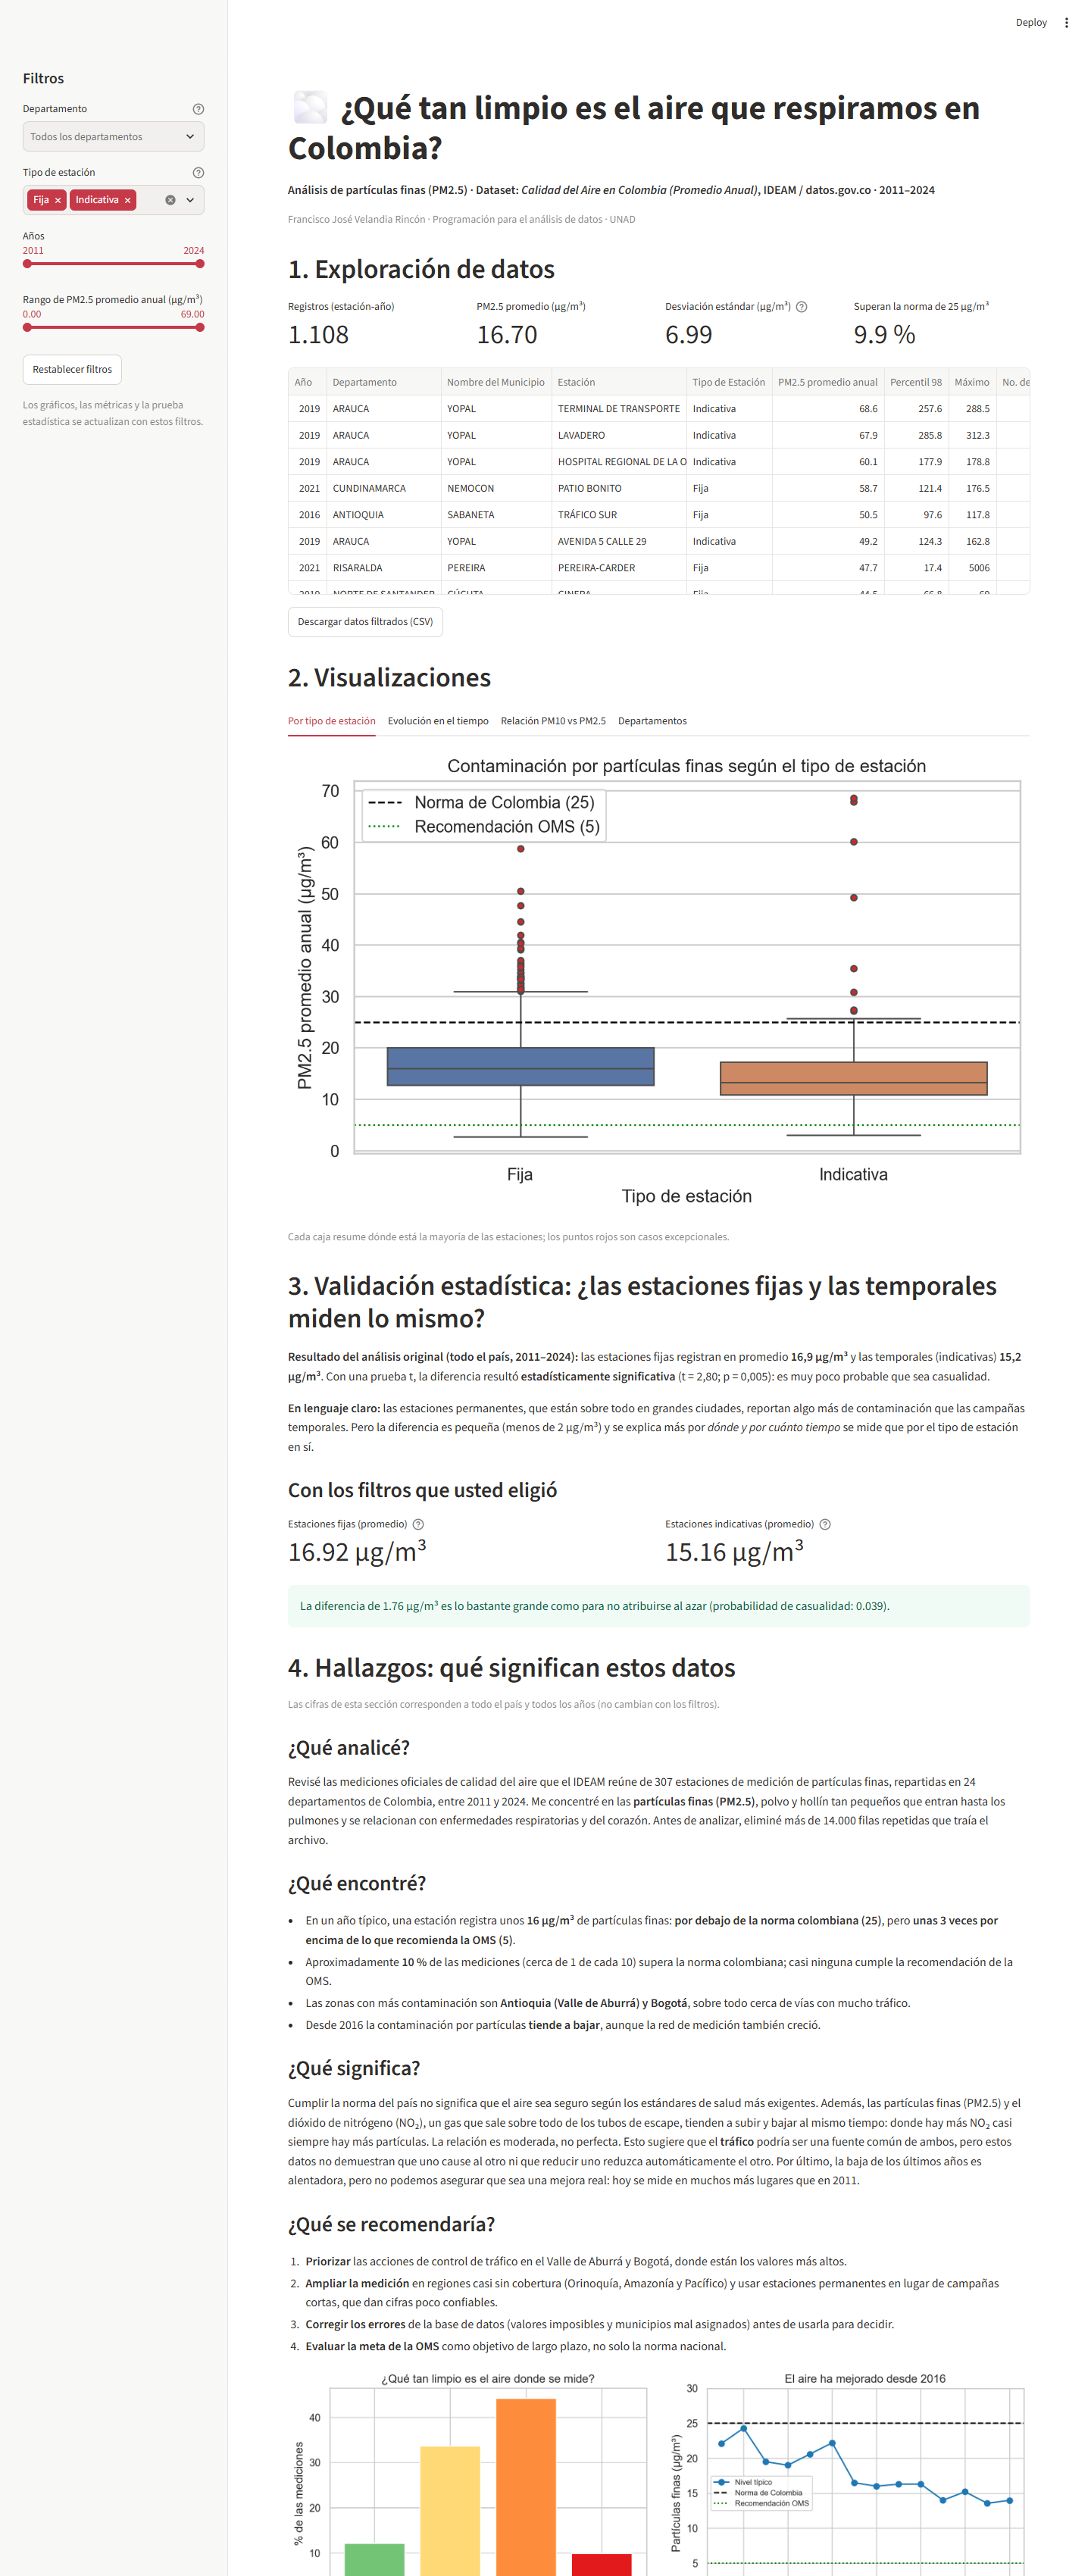

## 3. Ejercicios de Inteligencia Artificial

> **Herramienta de IA utilizada en toda la tarea:** Claude (Anthropic), a través de Claude Code. Los prompts, salidas y decisiones se documentan a continuación, junto con la Bitácora de IA al final.

### Ejercicio IA T4-A — Comparación de prompts para generación del dashboard

#### 1. Los dos prompts completos

**Prompt vago (ejecutado exactamente como lo indica la guía):**

> *"Hazme un dashboard en Streamlit de mi EDA de calidad del aire en Colombia."*

**Prompt específico:**

> *"Construye un dashboard en Streamlit (archivo único `app.py`) para mi EDA del dataset **Calidad del Aire en Colombia (Promedio Anual)** del IDEAM (`dataset.csv`, separador de miles con coma → `pd.read_csv(..., thousands=',')`). Limpieza: eliminar duplicados exactos y por clave (ID Estacion, Variable, Tiempo de exposición, Año) y normalizar 'Nombre del Departamento' (sin tildes, mayúsculas). Trabaja solo con PM2.5 de 24 horas. **Variables principales:** `Tipo de Estación` (categórica: Fija/Indicativa), `Promedio` (PM2.5 anual en µg/m³, numérica) y `Año` (numérica). **Filtros en el sidebar:** `st.multiselect` por Departamento y por Tipo de Estación, `st.slider` por Año y por rango de Promedio; todo debe actualizarse dinámicamente. **Secciones:** (1) Exploración: `st.dataframe` filtrable y `st.metric` con media, desviación estándar, conteo y % que supera la norma de 25 µg/m³; (2) Visualizaciones: al menos 3 gráficos con matplotlib/seaborn (boxplot por tipo de estación, tendencia anual, dispersión PM10 vs PM2.5, barras por departamento) con títulos y ejes en lenguaje no técnico; (3) Validación estadística: t-test (`ttest_ind`) entre estaciones fijas e indicativas, con interpretación en lenguaje claro y sin jerga; (4) Hallazgos con la estructura ¿Qué analicé? ¿Qué encontré? ¿Qué significa? ¿Qué se recomendaría?, mínimo 150 palabras e incluyendo 2 gráficos. **Audiencia:** directivo o tomador de decisiones sin formación estadística: no uses 'p-value', 'correlación de Pearson' ni 'desviación estándar' sin explicarlos, y no afirmes causalidad. Incluye `st.set_page_config(layout='wide')` y comentarios en el código."*

#### 2. Comparación de outputs

| Criterio | Prompt vago | Prompt específico |
|---|---|---|
| Líneas de código | 24 | 253 (`app.py` v1, antes de la revisión del Ejercicio T4-B) |
| ¿Corre sobre mi dataset? | **No.** Falla de inmediato: `FileNotFoundError: 'calidad_aire_colombia.csv'`. Aun con el archivo correcto fallaría, porque inventa las columnas `ciudad`, `pm25` y `fecha`, que no existen en el dataset. | **Sí.** Carga y limpia el dataset real y se ejecuta sin errores. Lo verifiqué con `streamlit.testing.AppTest` y en el navegador. |
| Filtros | 1 `selectbox` (ciudad inexistente) | 2 `multiselect` + 2 `slider`, que actualizan métricas, tabla y gráficos |
| Métricas | 1 (promedio) | 4 (registros, media, desviación estándar, % sobre la norma) |
| Gráficos | 1 (línea) | 6 (4 en pestañas + 2 en la narrativa) |
| Prueba estadística | No | Sí, con interpretación en lenguaje claro |
| Narrativa para no técnicos | No | Sí, con las 4 preguntas |
| Código funcional | ≈ 0 % (hay que rehacerlo) | ≈ 90 % (solo ajustes menores) |

**¿Cuál fue más útil?** El específico, sin comparación. El vago produjo una plantilla genérica que parece un dashboard pero **no sabe nada de mi dataset**; casi todo el esfuerzo posterior sería corregirlo.

El código del prompt vago (guardado tal cual en `ejercicios_ia/salida_prompt_vago.py`):

In [ ]:
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.title("Dashboard de Calidad del Aire en Colombia")

# Cargar datos
df = pd.read_csv("calidad_aire_colombia.csv")

# Filtros
ciudad = st.sidebar.selectbox("Selecciona una ciudad", df["ciudad"].unique())
df_filtrado = df[df["ciudad"] == ciudad]

# Métricas
st.metric("Promedio PM2.5", round(df_filtrado["pm25"].mean(), 2))

# Gráfico
fig, ax = plt.subplots()
ax.plot(df_filtrado["fecha"], df_filtrado["pm25"])
ax.set_title("PM2.5 en el tiempo")
st.pyplot(fig)

# Tabla
st.dataframe(df_filtrado)

#### 3. ¿Qué elementos del prompt específico marcaron la mayor diferencia?

1. **Nombre y estructura real del dataset** (`thousands=','`, nombres de columnas, duplicados): evita que la IA invente columnas. Fue el elemento decisivo.
2. **Filtros concretos por tipo de widget y variable** (`multiselect`, `slider`): convierte un requisito vago en código verificable.
3. **Secciones y métricas exigidas**: sin esto, la IA entrega el mínimo (una métrica y un gráfico).
4. **Audiencia no técnica con restricciones explícitas** (no usar "p-value", no afirmar causalidad): cambió el tono de los textos y evitó jerga.
5. **Reglas de limpieza** (duplicados por clave): sin ellas los promedios y conteos habrían sido incorrectos (47 % de filas duplicadas).

#### 4. ¿Usé alguno como base para mi dashboard real? ¿Qué modifiqué y por qué?

Usé la **salida del prompt específico** como base. El prompt vago no sirvió. Lo que modifiqué:

- **Narrativa:** la revisé y ajusté con mis propios hallazgos del EDA de la Tarea 3 (cifras, advertencias sobre el crecimiento de la red y los registros de Yopal), porque la IA no conoce mis conclusiones.
- **Resultado de la prueba t:** incluí el valor original de la Tarea 3 (t = 2,80; p = 0,005) y agregué la prueba recalculada con los filtros usando Welch (`equal_var=False`), porque en la Tarea 3 las varianzas de los grupos eran distintas.
- **Validaciones de interfaz:** mensajes cuando los filtros no dejan datos o falta un tipo de estación (`st.stop()`, `st.info`), y un mínimo de 5 registros para comparar departamentos, para no sacar conclusiones con muy pocos datos.
- **Cifras verificadas:** comprobé que las métricas del dashboard coinciden con la Tarea 3 (1.108 registros, media 16,70, desviación 6,99, 9,9 % sobre la norma).
- **Cambios posteriores** por la revisión de IA: ver Ejercicio T4-B.

### Ejercicio IA T4-B — IA como revisora del código del dashboard

Con el dashboard funcionando localmente, le pasé `app.py` (versión 1, 253 líneas; guardada en `ejercicios_ia/app_v1_antes_de_revision.py`) a la IA con el prompt de la guía:

> *"Revisa el siguiente código de Streamlit. Evalúa: 1. eficiencia del código y posibles optimizaciones. 2. experiencia del usuario: ¿los filtros son intuitivos y los gráficos son claros?. 3. claridad de la narrativa para audiencia no técnica. 4. buenas prácticas de Streamlit que no estoy aplicando."* + [código de `app.py`]

#### 1. Sugerencias completas de la IA y 2. Decisión justificada

| # | Área | Sugerencia de la IA | Decisión | Justificación |
|---|---|---|---|---|
| 1 | Eficiencia | Cerrar cada figura con `plt.close(fig)` tras `st.pyplot`; con cada cambio de filtro se crean figuras nuevas que quedan en memoria. | **Acepto** | Es un problema real en apps de larga duración (Streamlit Cloud tiene memoria limitada). Creé la función `mostrar(fig)` que muestra y cierra. |
| 2 | Buenas prácticas | La ruta `'dataset.csv'` es relativa al directorio de ejecución; usar `Path(__file__).parent` y manejar `FileNotFoundError` con un mensaje claro. | **Acepto** | Evita que la app falle en otro directorio o en el despliegue, y el mensaje orienta al usuario hacia el README. |
| 3 | Buenas prácticas | Agregar `show_spinner` a `@st.cache_data` para que el usuario sepa que está cargando. | **Acepto** | La primera carga limpia 29.683 filas y tarda; el mensaje evita que parezca congelada. Costo mínimo. |
| 4 | UX | Agregar un botón "Restablecer filtros"; con cuatro filtros es fácil perderse. La IA proponía envolver los filtros en `st.form` con botón de envío. | **Adapto** | Acepto el botón, pero con `key` en cada widget y un *callback* sobre `st.session_state`. Rechazo el `st.form`: obliga a pulsar "Aplicar" y pierde la actualización inmediata que pide la guía. |
| 5 | Narrativa | Las cifras de la narrativa (516 estaciones, "16 µg/m³", "1 de cada 10") están escritas a mano y se desactualizarían si cambian los datos; calcularlas. | **Adapto** | Calculo con el código las cifras generales (estaciones, mediana, % que supera la norma, veces sobre la OMS). Dejo fijas las del resultado de la prueba t, porque son *el resultado reportado en la Tarea 3* y no deben cambiar. Además descubrí que "516 estaciones" era el total del dataset y solo 307 miden PM2.5; lo corregí. |
| 6 | UX / diseño | Cambiar matplotlib/seaborn por Plotly para tener gráficos con *tooltips*, zoom y mejor interactividad. | **Rechazo** | La guía pide reutilizar los gráficos de la Tarea 3 (matplotlib/seaborn). Plotly agrega una dependencia y obliga a rehacer los gráficos. Los filtros ya aportan la interactividad principal. Podría ser una mejora futura. |
| 7 | UX | Dividir la app en varias páginas (multipágina) para hacerla más ligera. | **Rechazo** | El contenido es un recorrido corto y lineal (exploración → gráficos → prueba → hallazgos). Una sola página con pestañas es más simple de mantener y de usar para un directivo. |
| 8 | Narrativa | Poner la sección de "Hallazgos" al inicio, porque un directivo quiere primero las conclusiones. | **Rechazo** | La guía define el orden de las secciones, y los hallazgos se entienden mejor después de ver los datos. Mitigo el problema con un título claro y una sola página de recorrido corto. |
| 9 | Eficiencia | Crear una función genérica para dibujar los gráficos y evitar repetición. | **Rechazo** | Cada gráfico (boxplot, línea con eje doble, regresión, barras) tiene estructura distinta; una función genérica tendría tantos parámetros que sería menos legible que el código actual. Sí extraje `mostrar(fig)` (sugerencia 1), que es lo que realmente se repetía. |
| 10 | UX / accesibilidad | El gráfico de categorías usa verde-amarillo-naranja-rojo, difícil de distinguir con daltonismo. | **Rechazo (por ahora)** | Lo reconozco como limitación válida. Cada barra tiene su etiqueta en el eje X, por lo que el color no es la única señal. Queda como mejora futura con una paleta apta para daltonismo. |

**Resumen:** 3 aceptadas, 2 adaptadas, 5 rechazadas con justificación.

#### 3. Código final de `app.py` (después de aplicar los cambios aceptados y adaptados)

In [ ]:
"""Dashboard interactivo - Calidad del aire en Colombia (PM2.5).

Extensión comunicativa del EDA de la Tarea 3.
Estudiante: Francisco José Velandia Rincón - UNAD - Programación para el análisis de datos.
"""
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import streamlit as st
from scipy import stats

RUTA_DATOS = Path(__file__).parent / 'dataset.csv'
NORMA_COLOMBIA = 25   # µg/m³, norma anual colombiana (Res. 2254/2017)
GUIA_OMS = 5          # µg/m³, guía anual OMS 2021
CATEGORIAS = ['Bajo (≤10)', 'Moderado (10-15]', 'Alto (15-25]', 'Excede norma (>25)']

def mostrar(fig):
    """Muestra la figura en Streamlit y la cierra para liberar memoria."""
    st.pyplot(fig)
    plt.close(fig)


st.set_page_config(page_title='Calidad del aire en Colombia', page_icon='🌫️', layout='wide')
sns.set_theme(style='whitegrid')


# ----------------------------------------------------------------------------
# Carga y limpieza (misma lógica de la Tarea 3)
# ----------------------------------------------------------------------------
@st.cache_data(show_spinner='Cargando datos...')
def cargar_datos():
    df = pd.read_csv(RUTA_DATOS, thousands=',')
    claves = ['ID Estacion', 'Variable', 'Tiempo de exposición (horas)', 'Año']
    df = df.drop_duplicates().drop_duplicates(subset=claves).reset_index(drop=True)
    df['Departamento'] = df['Nombre del Departamento'].apply(
        lambda s: unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper().strip())
    pm25 = df[(df['Variable'] == 'PM2.5') & (df['Tiempo de exposición (horas)'] == 24)].copy()
    pm25['Categoría'] = pd.cut(pm25['Promedio'], [0, 10, 15, 25, np.inf], labels=CATEGORIAS)
    pm10 = df[(df['Variable'] == 'PM10') & (df['Tiempo de exposición (horas)'] == 24)]
    return pm25, pm10


try:
    pm25, pm10 = cargar_datos()
except FileNotFoundError:
    st.error('No se encontró el archivo dataset.csv junto a app.py. Revise el README para descargarlo.')
    st.stop()

# ----------------------------------------------------------------------------
# Sidebar: filtros
# ----------------------------------------------------------------------------
with st.sidebar:
    st.header('Filtros')
    deptos = sorted(pm25['Departamento'].unique())
    sel_deptos = st.multiselect('Departamento', deptos, default=[], key='f_deptos', placeholder='Todos los departamentos',
                                help='Deje vacío para ver el país completo.')
    sel_tipo = st.multiselect('Tipo de estación', ['Fija', 'Indicativa'], default=['Fija', 'Indicativa'], key='f_tipo',
                              help='Fija: permanente. Indicativa: campaña temporal de medición.')
    a_min, a_max = int(pm25['Año'].min()), int(pm25['Año'].max())
    rango_anio = st.slider('Años', a_min, a_max, (a_min, a_max), key='f_anio')
    rango_pm = st.slider('Rango de PM2.5 promedio anual (µg/m³)', 0.0, float(np.ceil(pm25['Promedio'].max())),
                         (0.0, float(np.ceil(pm25['Promedio'].max()))), step=0.5, key='f_pm')
    st.button('Restablecer filtros',
              on_click=lambda: [st.session_state.pop(k, None) for k in ('f_deptos', 'f_tipo', 'f_anio', 'f_pm')])
    st.caption('Los gráficos, las métricas y la prueba estadística se actualizan con estos filtros.')


def filtrar(d):
    d = d[d['Año'].between(*rango_anio)]
    if sel_deptos:
        d = d[d['Departamento'].isin(sel_deptos)]
    return d


f = filtrar(pm25)
f = f[f['Tipo de Estación'].isin(sel_tipo) & f['Promedio'].between(*rango_pm)]
f10 = filtrar(pm10)

# ----------------------------------------------------------------------------
# Encabezado
# ----------------------------------------------------------------------------
st.title('🌫️ ¿Qué tan limpio es el aire que respiramos en Colombia?')
st.markdown('**Análisis de partículas finas (PM2.5) · Dataset: _Calidad del Aire en Colombia (Promedio Anual)_, '
            'IDEAM / datos.gov.co · 2011–2024**')
st.caption('Francisco José Velandia Rincón · Programación para el análisis de datos · UNAD')

if f.empty:
    st.warning('Los filtros actuales no dejan ningún registro. Amplíe la selección en la barra lateral.')
    st.stop()

# ----------------------------------------------------------------------------
# Exploración de datos
# ----------------------------------------------------------------------------
st.header('1. Exploración de datos')
c1, c2, c3, c4 = st.columns(4)
c1.metric('Registros (estación-año)', f'{len(f):,}'.replace(',', '.'))
c2.metric('PM2.5 promedio (µg/m³)', f"{f['Promedio'].mean():.2f}")
c3.metric('Desviación estándar (µg/m³)', f"{f['Promedio'].std():.2f}" if len(f) > 1 else 'n/d',
          help='Qué tanto se alejan los valores del promedio: más alta = más desigualdad entre estaciones.')
c4.metric('Superan la norma de 25 µg/m³', f"{(f['Promedio'] > NORMA_COLOMBIA).mean() * 100:.1f} %")

cols_tabla = ['Año', 'Departamento', 'Nombre del Municipio', 'Estación', 'Tipo de Estación',
              'Promedio', 'Percentil 98', 'Máximo', 'No. de datos']
st.dataframe(f[cols_tabla].sort_values('Promedio', ascending=False).rename(columns={'Promedio': 'PM2.5 promedio anual'}),
             width='stretch', hide_index=True, height=300)
st.download_button('Descargar datos filtrados (CSV)', f[cols_tabla].to_csv(index=False).encode('utf-8'),
                   file_name='pm25_filtrado.csv', mime='text/csv')

# ----------------------------------------------------------------------------
# Visualizaciones
# ----------------------------------------------------------------------------
st.header('2. Visualizaciones')
tab1, tab2, tab3, tab4 = st.tabs(['Por tipo de estación', 'Evolución en el tiempo',
                                  'Relación PM10 vs PM2.5', 'Departamentos'])

with tab1:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    orden = [t for t in ['Fija', 'Indicativa'] if t in f['Tipo de Estación'].unique()]
    sns.boxplot(data=f, x='Tipo de Estación', y='Promedio', order=orden, hue='Tipo de Estación', legend=False,
                palette={'Fija': '#4c72b0', 'Indicativa': '#dd8452'}, flierprops={'markerfacecolor': '#d62728', 'markersize': 4}, ax=ax)
    ax.axhline(NORMA_COLOMBIA, color='black', ls='--', lw=1.2, label='Norma de Colombia (25)')
    ax.axhline(GUIA_OMS, color='green', ls=':', lw=1.2, label='Recomendación OMS (5)')
    ax.set(title='Contaminación por partículas finas según el tipo de estación',
           xlabel='Tipo de estación', ylabel='PM2.5 promedio anual (µg/m³)')
    ax.legend(loc='upper left')
    mostrar(fig)
    st.caption('Cada caja resume dónde está la mayoría de las estaciones; los puntos rojos son casos excepcionales.')

with tab2:
    serie = f.groupby('Año')['Promedio'].agg(['median', 'count'])
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(serie.index, serie['median'], marker='o', color='#1f77b4', label='PM2.5 típico (mediana)')
    ax.axhline(NORMA_COLOMBIA, color='black', ls='--', lw=1.2, label='Norma de Colombia (25)')
    ax.set(title='¿Ha mejorado el aire? Evolución anual de las partículas finas', xlabel='Año',
           ylabel='PM2.5 típico (µg/m³)')
    ax2 = ax.twinx()
    ax2.bar(serie.index, serie['count'], alpha=0.15, color='gray', label='Mediciones disponibles')
    ax2.set_ylabel('Número de mediciones'); ax2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc='upper right')
    ax.set_ylim(bottom=0)
    mostrar(fig)
    st.caption('Las barras grises muestran que la red de medición creció con los años: parte de la mejora '
               'aparente puede deberse a que hoy se mide en más lugares.')

with tab3:
    ancho = (f[['ID Estacion', 'Año', 'Promedio']].rename(columns={'Promedio': 'PM2.5'})
             .merge(f10[['ID Estacion', 'Año', 'Promedio']].rename(columns={'Promedio': 'PM10'}),
                    on=['ID Estacion', 'Año']))
    if len(ancho) < 3:
        st.info('No hay suficientes estaciones con ambas mediciones para esta selección.')
    else:
        r = ancho['PM10'].corr(ancho['PM2.5'])
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.regplot(data=ancho, x='PM10', y='PM2.5', scatter_kws={'alpha': 0.5, 's': 25, 'color': '#4c72b0'},
                    line_kws={'color': '#d62728'}, ax=ax)
        ax.set(title='Partículas gruesas (PM10) y finas (PM2.5): suelen subir juntas',
               xlabel='Partículas gruesas PM10 (µg/m³)', ylabel='Partículas finas PM2.5 (µg/m³)')
        mostrar(fig)
        st.caption(f'{len(ancho)} estaciones-año con ambas mediciones. Asociación entre ambas: {r:.2f} '
                   '(1 = suben exactamente juntas, 0 = sin relación). Asociación no implica que una cause la otra.')

with tab4:
    top = f.groupby('Departamento')['Promedio'].agg(['mean', 'count'])
    top = top[top['count'] >= 5].sort_values('mean', ascending=True).tail(15)
    if top.empty:
        st.info('Se necesitan al menos 5 registros por departamento para compararlos.')
    else:
        fig, ax = plt.subplots(figsize=(9, 0.4 * len(top) + 1.5))
        ax.barh(top.index, top['mean'], color='#e6550d')
        ax.axvline(NORMA_COLOMBIA, color='black', ls='--', lw=1.2, label='Norma de Colombia (25)')
        ax.set(title='Departamentos con más partículas finas (promedio de sus estaciones)',
               xlabel='PM2.5 promedio (µg/m³)', ylabel='')
        ax.legend(loc='lower right')
        mostrar(fig)
        st.caption('Solo se muestran departamentos con al menos 5 registros, para no sacar conclusiones con muy pocos datos.')

# ----------------------------------------------------------------------------
# Validación estadística
# ----------------------------------------------------------------------------
st.header('3. Validación estadística: ¿las estaciones fijas y las temporales miden lo mismo?')
st.markdown(
    '**Resultado del análisis original (todo el país, 2011–2024):** las estaciones fijas registran en promedio '
    '**16,9 µg/m³** y las temporales (indicativas) **15,2 µg/m³**. Con una prueba t, la diferencia resultó '
    '**estadísticamente significativa** (t = 2,80; p = 0,005): es muy poco probable que sea casualidad.')
st.markdown('**En lenguaje claro:** las estaciones permanentes, que están sobre todo en grandes ciudades, '
            'reportan algo más de contaminación que las campañas temporales. Pero la diferencia es pequeña '
            '(menos de 2 µg/m³) y se explica más por *dónde y por cuánto tiempo* se mide que por el tipo de estación en sí.')

fija = f.loc[f['Tipo de Estación'] == 'Fija', 'Promedio']
indic = f.loc[f['Tipo de Estación'] == 'Indicativa', 'Promedio']
st.subheader('Con los filtros que usted eligió')
if len(fija) >= 3 and len(indic) >= 3:
    t, p = stats.ttest_ind(fija, indic, equal_var=False)
    a, b = st.columns(2)
    a.metric('Estaciones fijas (promedio)', f'{fija.mean():.2f} µg/m³', help=f'{len(fija)} registros')
    b.metric('Estaciones indicativas (promedio)', f'{indic.mean():.2f} µg/m³', help=f'{len(indic)} registros')
    if p < 0.05:
        st.success(f'La diferencia de {abs(fija.mean() - indic.mean()):.2f} µg/m³ es lo bastante grande como para '
                   f'no atribuirse al azar (probabilidad de casualidad: {p:.3f}).')
    else:
        st.info(f'Con esta selección, la diferencia de {abs(fija.mean() - indic.mean()):.2f} µg/m³ podría deberse '
                f'al azar (probabilidad de casualidad: {p:.3f}); no hay evidencia suficiente de que sean distintas.')
else:
    st.info('Para comparar, la selección debe incluir ambos tipos de estación con al menos 3 registros cada uno.')

# ----------------------------------------------------------------------------
# Hallazgos / narrativa para audiencia no técnica
# ----------------------------------------------------------------------------
st.header('4. Hallazgos: qué significan estos datos')
st.caption('Las cifras de esta sección corresponden a todo el país y todos los años (no cambian con los filtros).')

n_est = pm25['ID Estacion'].nunique()
mediana_pm = pm25['Promedio'].median()
pct_excede = (pm25['Promedio'] > NORMA_COLOMBIA).mean() * 100

st.subheader('¿Qué analicé?')
st.write(f'Revisé las mediciones oficiales de calidad del aire que el IDEAM reúne de {n_est} estaciones de medición de partículas finas, repartidas en 24 '
         'departamentos de Colombia, entre 2011 y 2024. Me concentré en las **partículas finas (PM2.5)**, polvo y hollín '
         'tan pequeños que entran hasta los pulmones y se relacionan con enfermedades respiratorias y del corazón. '
         'Antes de analizar, eliminé más de 14.000 filas repetidas que traía el archivo.')

st.subheader('¿Qué encontré?')
st.markdown(
    f'- En un año típico, una estación registra unos **{mediana_pm:.0f} µg/m³** de partículas finas: **por debajo de la norma '
    f'colombiana (25)**, pero **unas {mediana_pm / GUIA_OMS:.0f} veces por encima de lo que recomienda la OMS (5)**.\n'
    f'- Aproximadamente **{pct_excede:.0f} %** de las mediciones (cerca de 1 de cada 10) supera la norma colombiana; '
    'casi ninguna cumple la recomendación de la OMS.\n'
    '- Las zonas con más contaminación son **Antioquia (Valle de Aburrá) y Bogotá**, sobre todo cerca de vías con mucho tráfico.\n'
    '- Desde 2016 la contaminación por partículas **tiende a bajar**, aunque la red de medición también creció.')

st.subheader('¿Qué significa?')
st.write('Cumplir la norma del país no significa que el aire sea seguro según los estándares de salud más '
         'exigentes. Además, las partículas finas (PM2.5) y el dióxido de nitrógeno (NO₂), un gas que sale sobre todo de '
         'los tubos de escape, tienden a subir y bajar al mismo tiempo: donde hay más NO₂ casi siempre hay más partículas. '
         'La relación es moderada, no perfecta. Esto sugiere que el **tráfico** podría ser una fuente común de ambos, pero '
         'estos datos no demuestran que uno cause al otro ni que reducir uno reduzca automáticamente el otro. '
         'Por último, la baja de los últimos años es alentadora, pero no podemos asegurar que sea una mejora real: hoy se '
         'mide en muchos más lugares que en 2011.')

st.subheader('¿Qué se recomendaría?')
st.markdown(
    '1. **Priorizar** las acciones de control de tráfico en el Valle de Aburrá y Bogotá, donde están los valores más altos.\n'
    '2. **Ampliar la medición** en regiones casi sin cobertura (Orinoquía, Amazonía y Pacífico) y usar estaciones '
    'permanentes en lugar de campañas cortas, que dan cifras poco confiables.\n'
    '3. **Corregir los errores** de la base de datos (valores imposibles y municipios mal asignados) antes de usarla para decidir.\n'
    '4. **Evaluar la meta de la OMS** como objetivo de largo plazo, no solo la norma nacional.')

g1, g2 = st.columns(2)
with g1:
    conteo = pm25['Categoría'].value_counts().reindex(CATEGORIAS)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(conteo.index, conteo.values / conteo.sum() * 100, color=['#74c476', '#fed976', '#fd8d3c', '#e31a1c'])
    ax.set(title='¿Qué tan limpio es el aire donde se mide?', xlabel='Nivel de partículas finas (µg/m³)',
           ylabel='% de las mediciones')
    ax.tick_params(axis='x', labelsize=8)
    mostrar(fig)
with g2:
    anual = pm25.groupby('Año')['Promedio'].median()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(anual.index, anual.values, marker='o', color='#1f77b4', label='Nivel típico')
    ax.axhline(NORMA_COLOMBIA, color='black', ls='--', label='Norma de Colombia')
    ax.axhline(GUIA_OMS, color='green', ls=':', label='Recomendación OMS')
    ax.set(title='El aire ha mejorado desde 2016', xlabel='Año', ylabel='Partículas finas (µg/m³)', ylim=(0, 30))
    ax.legend(fontsize=8)
    mostrar(fig)

st.divider()
st.caption('Fuente: IDEAM – datos.gov.co. Código y documentación en el repositorio de GitHub del proyecto.')

### Ejercicio IA T4-C — Error en comunicación de resultados estadísticos

**Prompt ejecutado (el del docente, completando los [...] con mis valores reales):**

> *"Tengo un análisis donde encontré que la correlación entre **NO₂ (dióxido de nitrógeno)** y **PM2.5** es de **0,56**. Escríbeme el texto para la sección de hallazgos del dashboard dirigido al gerente de una empresa que no sabe de estadística."*

(El valor 0,56 es el r de Pearson entre NO₂ y PM2.5 sobre 81 pares estación–año, calculado en la Parte 1 de la Tarea 3.)

#### 1. Texto generado por la IA

> **Hallazgos clave: el vínculo entre el NO₂ y las partículas PM2.5**
>
> Nuestro análisis revela una **correlación positiva moderada (r = 0,56)** entre el dióxido de nitrógeno (NO₂) y las partículas finas PM2.5. En términos sencillos, esto significa que **cuando aumenta el NO₂, también aumenta el PM2.5**, lo que confirma que ambos contaminantes están estrechamente ligados.
>
> **¿Qué implica para su empresa?** Dado que el NO₂ influye directamente en los niveles de PM2.5, **reducir las emisiones de NO₂ permitirá disminuir las partículas finas** y mejorar la calidad del aire. Recomendamos priorizar el monitoreo del NO₂ como indicador principal y diseñar estrategias de mitigación enfocadas en él.

#### 2. Evaluación crítica

- **¿Comunicó la correlación sin afirmar causalidad?** **No: comete exactamente el error que se buscaba detectar.** Aunque empieza bien ("correlación"), después dice que "el NO₂ **influye directamente** en el PM2.5" y que "reducir el NO₂ **permitirá disminuir** las partículas". Eso es una afirmación causal que los datos no sostienen. La explicación más probable es una **causa común** (el tráfico emite ambos), no que uno cause al otro. Además "confirma que están estrechamente ligados" exagera: 0,56 es moderada, y explica solo ~31 % de la variación (r² ≈ 0,31).
- **¿El lenguaje es realmente accesible?** **Solo en parte; usa jerga disfrazada.** "Correlación positiva moderada (r = 0,56)" y "NO₂" siguen siendo términos técnicos que el gerente no puede interpretar, y no explica qué es el NO₂ ni de dónde sale. La frase "en términos sencillos" no cambia el vocabulario del párrafo.
- **¿Es conciso y accionable o vago y académico?** **Es vago.** "Priorizar el monitoreo", "diseñar estrategias de mitigación enfocadas" no dicen dónde, quién ni qué hacer. Tampoco menciona las limitaciones (solo 81 mediciones comparables), por lo que transmite una seguridad excesiva.

#### 3. Texto corregido (el que aparece en mi dashboard, sección *Hallazgos → ¿Qué significa?*)

> Las partículas finas (PM2.5) y el dióxido de nitrógeno (NO₂), un gas que sale sobre todo de los tubos de escape, tienden a subir y bajar al mismo tiempo: donde hay más NO₂ casi siempre hay más partículas. La relación es moderada, no perfecta. Esto sugiere que el **tráfico** podría ser una fuente común de ambos, pero estos datos no demuestran que uno cause al otro ni que reducir uno reduzca automáticamente el otro.
>
> **Recomendación:** concentrar el control de emisiones de vehículos en las zonas de más tráfico (Valle de Aburrá y Bogotá) y ampliar la medición de NO₂, hoy disponible en pocas estaciones, antes de decidir inversiones.

Qué corregí: eliminé "r = 0,56" y "correlación" sustituyéndolos por una descripción en lenguaje cotidiano ("tienden a subir y bajar al mismo tiempo"); expliqué qué es el NO₂ y de dónde sale; cambié "influye directamente / permitirá disminuir" por una hipótesis explícita (causa común: el tráfico) y una advertencia de que no se demuestra causalidad; cambié "confirma" por "sugiere"; y reemplacé la recomendación vaga por una acción concreta con lugares y un siguiente paso (más mediciones), reconociendo la limitación de datos.

#### 4. Reflexión

Pedirle a la IA que comunique para no técnicos **sin errores de causalidad ni jerga** es más difícil de lo que parece, porque ambos objetivos chocan. Un texto simple y directo tiende a sonar causal ("esto provoca aquello"), y un texto cuidadoso tiende a sonar técnico. La IA resolvió ese conflicto sacrificando la rigurosidad: lo que hizo fue completar la frase que suena más persuasiva para un gerente. Además, el prompt del docente ya inducía el sesgo: pedía un texto "para el gerente" y no mencionaba las limitaciones. Me di cuenta de que para obtener un buen resultado hay que **pedir explícitamente** lo que uno quiere evitar (no afirmar causalidad, definir cada término, incluir una limitación) y, sobre todo, **leer el resultado con espíritu crítico**: el error no se ve a primera vista porque el texto está bien escrito. La conclusión es que la IA sirve como borrador, pero la responsabilidad de verificar que el mensaje no sea más fuerte que la evidencia sigue siendo mía.

## 4. Bitácora de IA general – Tarea 4

| Campo | Registro |
|---|---|
| **¿Usaste IA en esta tarea?** | Sí (Claude, mediante Claude Code) |
| **Prompt exacto utilizado** | Los prompts de los tres ejercicios (T4-A, T4-B y T4-C), documentados arriba textualmente. Además, para construir el proyecto (estructura del repositorio, `README.md`, `requirements.txt` y el borrador del notebook) se pidió a la IA desarrollar la tarea siguiendo la guía del docente. |
| **Resumen del output recibido** | Código base de `app.py` (dashboard con filtros, métricas, 4 gráficos, prueba t y narrativa), README, requirements, capturas del dashboard y el borrador de este notebook con los tres ejercicios. |
| **¿Qué modificaste y por qué?** | Verifiqué que las cifras del dashboard coincidieran con mi EDA de la Tarea 3 (1.108 registros, media 16,70, desviación 6,99, 9,9 % sobre la norma, t = 2,80, p = 0,005). Aplicué, adapté o rechacé las sugerencias de revisión según el Ejercicio T4-B, y corregí el texto de causalidad del Ejercicio T4-C. |
| **¿Qué aprendiste o qué error detectaste?** | Un prompt vago produce código que no corre con datos reales; uno específico produce código utilizable. La IA tiende a afirmar causalidad al comunicar correlaciones a audiencias no técnicas. Una cifra escrita a mano en la narrativa ("516 estaciones") resultó ser incorrecta para el PM2.5 (son 307): conviene calcularlas desde los datos. |

## 5. Referencias bibliográficas (APA)

- Instituto de Hidrología, Meteorología y Estudios Ambientales – IDEAM. (2026). *Calidad del aire en Colombia (promedio anual)* [Conjunto de datos]. Portal de Datos Abiertos de Colombia. https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Calidad-Del-Aire-En-Colombia-Promedio-Anual-/kekd-7v7h
- McKinney, W. (2022). *Python for data analysis: Data wrangling with pandas, NumPy, and Jupyter* (3.ª ed.). O'Reilly Media. https://wesmckinney.com/book/
- Ministerio de Ambiente y Desarrollo Sostenible. (2017). *Resolución 2254 de 2017: Por la cual se adopta la norma de calidad del aire ambiente y se dictan otras disposiciones*. República de Colombia.
- Streamlit Inc. (s. f.). *Streamlit documentation*. https://docs.streamlit.io
- GitHub, Inc. (s. f.). *GitHub Docs*. https://docs.github.com
- World Health Organization. (2021). *WHO global air quality guidelines: Particulate matter (PM2.5 and PM10), ozone, nitrogen dioxide, sulfur dioxide and carbon monoxide*. World Health Organization. https://www.who.int/publications/i/item/9789240034228